In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.discrete.count_model import ZeroInflatedPoisson
from scipy.stats import weibull_min
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
from scipy.stats import nbinom
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import lognorm, pareto, poisson, weibull_min
from scipy.stats import anderson, kstest, cramervonmises

In [2]:
#u_value = 0.95

## 1. Datos

### 1.1 Frecuencia

In [2]:
panel = pd.read_csv('panel_SPP.csv')

print(panel['n_siniestros'].sum())

print(panel["exposicion_anual"].sum())

panel

44
1871.9963470319635


,Poliza,Fecha Ini,Fecha Fin,Duración,anio,exposicion_anual,n_siniestros,_merge
0,00000005,2020-07-26,2021-07-26,365,2020,0.434426,0,left_only
1,00000005,2020-07-26,2021-07-26,365,2021,0.567123,1,both
2,DV00000001,2023-03-31,2023-07-19,110,2023,0.304110,0,left_only
3,EC00000003,2020-09-01,2023-09-01,1095,2020,0.333333,0,left_only
4,EC00000003,2020-09-01,2023-09-01,1095,2021,1.000000,0,left_only
...,...,...,...,...,...,...,...,...
3541,RTMQ00000044,2024-12-18,2025-12-18,365,2025,0.964384,0,left_only
3542,RTMQ00000051,2024-05-12,2025-05-12,365,2024,0.639344,0,left_only
3543,RTMQ00000051,2024-05-12,2025-05-12,365,2025,0.361644,0,left_only
3544,RTQM00000012,2023-05-12,2024-05-12,366,2023,0.641096,0,left_only


In [3]:
######### Exposición anual

desc_expo = panel["exposicion_anual"].describe()
desc_expo

count    3546.000000
mean        0.527918
std         0.288954
min         0.002732
25%         0.279452
50%         0.526027
75%         0.767600
max         1.000000
Name: exposicion_anual, dtype: float64

In [4]:
######### Distribución de siniestros

freq_counts = panel["n_siniestros"].value_counts().sort_index()

freq_table = pd.DataFrame({
    "n_siniestros": freq_counts.index,
    "frecuencia": freq_counts.values,
    "proporción": freq_counts.values / freq_counts.sum()
})

freq_table


,n_siniestros,frecuencia,proporción
0,0,3523,0.993514
1,1,19,0.005358
2,2,2,0.000564
3,3,1,0.000282
4,18,1,0.000282


### 1.2. Pólizas en vigor

Las pólizas en vigor se utilizan como base para las simulaciones de pérdidas anuales.

In [7]:
# Leer solo la pestaña y columna necesarias
df_pol = pd.read_excel(
    "Polizas Vigor pesos-dol con vigencias.xlsx",
#    sheet_name="Pesos Básica Depurada",
#    header=1,
    usecols=["POL"]
)

# Convertir a lista (opcional: quitar NA)
lista_pol = df_pol["POL"].dropna().astype(str).unique().tolist()

In [8]:
panel_sub = panel[
    (panel["Poliza"].astype(str).isin(lista_pol)) #&
#    (panel["anio"] == 2026)
].copy()

In [8]:
print(panel_sub["Poliza"].nunique())

print(panel_sub["exposicion_anual"].sum())

panel_sub

415
558.7056890485815


,Poliza,Fecha Ini,Fecha Fin,Duración,anio,exposicion_anual,n_siniestros,_merge
762,EC00000505,2024-07-15,2027-07-15,1095,2024,0.464481,0,left_only
763,EC00000505,2024-07-15,2027-07-15,1095,2025,1.000000,0,left_only
764,EC00000505,2024-07-15,2027-07-15,1095,2026,1.000000,0,left_only
765,EC00000505,2024-07-15,2027-07-15,1095,2027,0.536986,0,left_only
814,EC00000539,2024-10-15,2025-10-15,365,2024,0.213115,0,left_only
...,...,...,...,...,...,...,...,...
3507,MEMP00000016,2025-07-26,2026-07-26,365,2026,0.567123,0,left_only
3508,MEMP00000017,2025-07-23,2026-07-23,365,2025,0.443836,0,left_only
3509,MEMP00000017,2025-07-23,2026-07-23,365,2026,0.558904,0,left_only
3540,RTMQ00000044,2024-12-18,2025-12-18,365,2024,0.038251,0,left_only


In [9]:
########### Exposición anual

desc_expo_vigor = panel_sub["exposicion_anual"].describe()
desc_expo_vigor

count    3544.000000
mean        0.527933
std         0.289031
min         0.002732
25%         0.279452
50%         0.526027
75%         0.768285
max         1.000000
Name: exposicion_anual, dtype: float64

### 1.3 Severidad


In [21]:
df_siniestros = pd.read_csv(
    "Siniestros_ramo_112.csv",
)

df_siniestros

,No. Reclamación,Año,Póliza,Producto,Suma Asegurada,Cobertura,Moneda,Estimado + aumento - disminución,Estimado + aumento - disminución.1,Unnamed: 9,Garantía,Monto,Fecha Ocurrido,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,1,2021.0,00000005,EQUIPO CONTRATISTAS,"422,100",Básica,10.0,"243,203.27","243,203.27","234,761.27","234,761.27",243203.27,21/05/2021,NaN,Promedio,"113,520.82",NaN
1,2,2022.0,EE00000051,EQUIPO ELECTRONICO,"21,545,940",EQUIPO ELECTRONICO,10.0,"24,975.54","24,975.54","22,477.99","22,477.99",24975.54,25/08/2022,NaN,Mínimo,"3,494.80",NaN
2,4,2022.0,EC00000173,EQUIPO CONTRATISTAS,"22,000",EQUIPO CONTRATISTAS,20.0,"29,200.00","584,000.00","445,304.79","445,304.79",584000.00,13/12/2022,NaN,Máximo,"1,527,849.37",NaN
3,DA-EE-0010,2023.0,EE00000051,EQUIPO ELECTRONICO,"21,545,940",ROBO,10.0,"20,000.00","20,000.00","15,000.00","15,000.00",20000.00,11/01/2023,NaN,NaN,Pagado,Estimado+aum-dism
4,DA-EC-0017,2023.0,EC00000194,EQUIPO CONTRATISTAS,"2,784,000",EQUIPO CONTRATISTAS,10.0,"1,527,849.37","1,527,849.37","1,472,169.37","1,472,169.37",1527849.37,14/06/2023,NaN,50%,"5,972.11","10,044.22"
5,DA-EC-0028,2023.0,EC00000231,EQUIPO CONTRATISTAS,"59,354",DAÑOS MATERIAL,20.0,"2,780.67","55,613.34","24,149.07","24,149.07",55613.34,14/08/2023,NaN,75%,"21,814.65","28,270.70"
6,DA-EC-0032,2023.0,EC00000194,EQUIPO CONTRATISTAS,"1,508,200",EQUIPO CONTRATISTAS,10.0,"102,659.75","102,659.75","102,659.75","102,659.75",102659.75,06/10/2023,NaN,90%,"227,888.50","283,889.32"
7,DA-EE-0033,2023.0,EE00000302,EQUIPO ELECTRONICO,"25,000",EQUIPO ELECTRONICO,10.0,"4,464.65","4,464.65","3,623.06","3,623.06",4464.65,25/10/2023,NaN,95%,"424,898.74","548,996.00"
8,DA-EE-0042,2023.0,EE00000182,EQUIPO ELECTRONICO,"611,470",ROBO,20.0,"65,256.37","1,305,127.40","1,132,337.89",NaN,1305127.40,18/09/2023,NaN,99%,"1,326,041.83","1,432,078.92"
9,DA-EE-0048,2023.0,EE00000214,EQUIPO ELECTRONICO,"34,481",ROBO,10.0,"30,213.80","30,213.80","21,593.54",NaN,30213.80,14/12/2023,NaN,99.50%,"1,399,105.60","1,479,964.15"


In [20]:
df_siniestros["Monto"]

0       243,203.27
1        24,975.54
2       584,000.00
3        20,000.00
4     1,527,849.37
5        55,613.34
6       102,659.75
7         4,464.65
8     1,305,127.40
9        30,213.80
10       32,040.53
11       13,792.24
12       62,929.31
13       20,646.55
14      350,640.00
15       18,591.33
16       27,623.00
17       15,087.93
18      301,326.20
19       10,044.22
20       10,044.22
21       10,044.22
22       10,044.22
23       10,044.22
24       10,044.22
25       10,044.22
26       10,044.22
27       10,044.22
28       10,044.22
29       10,044.22
30       10,044.22
31       10,044.22
32       10,044.22
33       10,044.22
34       10,044.22
35       10,044.22
36       10,044.22
37        6,523.03
38       17,240.52
39        3,494.80
40        4,477.63
41       19,978.00
42        6,900.00
43       14,721.93
44             NaN
45             NaN
46             NaN
47             NaN
48             NaN
49             NaN
Name: Monto, dtype: object

In [22]:
siniestros_pesos = df_siniestros[
    df_siniestros["Monto"] > 0
]

siniestros_pesos = siniestros_pesos["Monto"]

siniestros_pesos


0      243203.27
1       24975.54
2      584000.00
3       20000.00
4     1527849.37
5       55613.34
6      102659.75
7        4464.65
8     1305127.40
9       30213.80
10      32040.53
11      13792.24
12      62929.31
13      20646.55
14     350640.00
15      18591.33
16      27623.00
17      15087.93
18     301326.20
19      10044.22
20      10044.22
21      10044.22
22      10044.22
23      10044.22
24      10044.22
25      10044.22
26      10044.22
27      10044.22
28      10044.22
29      10044.22
30      10044.22
31      10044.22
32      10044.22
33      10044.22
34      10044.22
35      10044.22
36      10044.22
37       6523.03
38      17240.52
39       3494.80
40       4477.63
41      19978.00
42       6900.00
43      14721.93
Name: Monto, dtype: float64

In [23]:
# Descripción de percentiles

desc_sev = siniestros_pesos.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

pd.options.display.float_format = '{:,.0f}'.format
desc_sev

count          44
mean      113,521
std       309,162
min         3,495
50%        10,044
75%        28,271
90%       283,889
95%       548,996
99%     1,432,079
max     1,527,849
Name: Monto, dtype: float64

In [24]:
# Resumen de severidades

sev_summary = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Mínimo",
        "P25",
        "Mediana",
        "Media",
        "P75",
        "P90",
        "P95",
        "P99",
        "Máximo"
    ],
    "Valor": [
        siniestros_pesos.count(),
        siniestros_pesos.min(),
        siniestros_pesos.quantile(0.25),
        siniestros_pesos.median(),
        siniestros_pesos.mean(),
        siniestros_pesos.quantile(0.75),
        siniestros_pesos.quantile(0.90),
        siniestros_pesos.quantile(0.95),
        siniestros_pesos.quantile(0.99),
        siniestros_pesos.max()
    ]
})

sev_summary

,Estadístico,Valor
0,Observaciones,44
1,Mínimo,"3,495"
2,P25,"10,044"
3,Mediana,"10,044"
4,Media,"113,521"
5,P75,"28,271"
6,P90,"283,889"
7,P95,"548,996"
8,P99,"1,432,079"
9,Máximo,"1,527,849"


In [25]:
skewness = siniestros_pesos.skew()
kurtosis = siniestros_pesos.kurtosis()

pd.DataFrame({
    "Métrica": ["Asimetría", "Curtosis"],
    "Valor": [skewness, kurtosis]
})

,Métrica,Valor
0,Asimetría,4
1,Curtosis,15


## 2. Ajustar frecuencia

### 2.1. Poisson con inflación de cero

#### 2.1.1. Fit

In [26]:
y = panel["n_siniestros"]
X = sm.add_constant(pd.Series(1, index=panel.index))

zip_model = ZeroInflatedPoisson(
    y,
    X,
    exog_infl=X,
    offset=np.log(panel["exposicion_anual"]),
    inflation="logit"
)

zip_res = zip_model.fit(method="bfgs")
print(zip_res.summary())

Optimization terminated successfully.
         Current function value: 0.051125
         Iterations: 15
         Function evaluations: 27
         Gradient evaluations: 27
                     ZeroInflatedPoisson Regression Results                    
Dep. Variable:            n_siniestros   No. Observations:                 3546
Model:             ZeroInflatedPoisson   Df Residuals:                     3545
Method:                            MLE   Df Model:                            0
Date:                 Wed, 20 May 2026   Pseudo R-squ.:              -4.918e-09
Time:                         09:07:39   Log-Likelihood:                -181.29
converged:                        True   LL-Null:                       -181.29
Covariance Type:             nonrobust   LLR p-value:                       nan
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
inflate_0      4.5187      0.2

#### 3.1.2. Extraer parámetros

In [27]:
beta_pois = zip_res.params.loc[0]
beta_infl = zip_res.params.loc["inflate_0"]

lambda_hat = float(np.exp(beta_pois))
p_zero = float(1 / (1 + np.exp(-beta_infl)))

print("Lambda:", lambda_hat)
print("Prob cero estructural:", p_zero)

Lambda: 2.072086440426502
Prob cero estructural: 0.9892148997784275


#### 3.1.3. Validación

##### 3.1.3.1. Media

In [28]:
mu_hat = (
    panel["exposicion_anual"]
    * (1 - p_zero)
    * lambda_hat
)

mean_obs = panel["n_siniestros"].mean()

print("Media observada :", mean_obs)
print("Media modelada  :", mu_hat.mean())

Media observada : 0.012408347433728144
Media modelada  : 0.0117977263816925


##### 3.1.3.2 Varianza vs media

In [29]:
var_obs = panel["n_siniestros"].var()

print("Media:", mean_obs)
print("Varianza:", var_obs)
print("Var / Media:", var_obs / mean_obs)

Media: 0.012408347433728144
Varianza: 0.10139747044086837
Var / Media: 8.171714322348166


##### 3.1.3.3. Gráfica

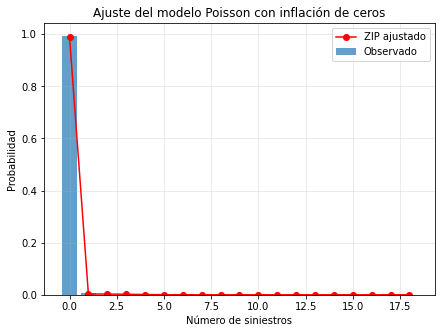

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

# Datos observados
y = panel["n_siniestros"]
counts_obs = y.value_counts().sort_index()
freq_obs = counts_obs / len(y)

# Parámetros del modelo
p0 = p_zero          # prob. de cero estructural
lam = lambda_hat     # intensidad Poisson

# Soporte
k = np.arange(0, counts_obs.index.max() + 1)

# Probabilidades teóricas ZIP
pmf_zip = np.zeros_like(k, dtype=float)
pmf_zip[0] = p0 + (1 - p0) * poisson.pmf(0, lam)
pmf_zip[1:] = (1 - p0) * poisson.pmf(k[1:], lam)

# Gráfica
plt.figure(figsize=(7,5))
plt.bar(freq_obs.index, freq_obs.values, alpha=0.7, label="Observado")
plt.plot(k, pmf_zip, marker="o", color="red", label="ZIP ajustado")

plt.xlabel("Número de siniestros")
plt.ylabel("Probabilidad")
plt.title("Ajuste del modelo Poisson con inflación de ceros")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


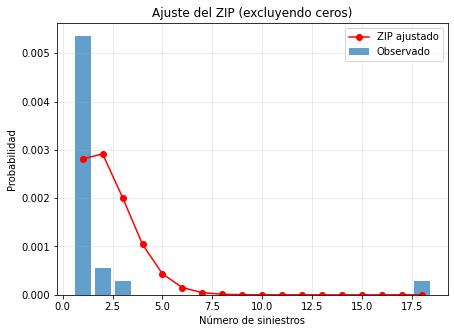

In [32]:
# Filtrar valores mayores a cero
k_pos = k[1:]
freq_obs_pos = freq_obs.loc[1:]
pmf_zip_pos = pmf_zip[1:]

plt.figure(figsize=(7,5))
plt.bar(freq_obs_pos.index, freq_obs_pos.values, alpha=0.7, label="Observado")
plt.plot(k_pos, pmf_zip_pos, marker="o", color="red", label="ZIP ajustado")

plt.xlabel("Número de siniestros")
plt.ylabel("Probabilidad")
plt.title("Ajuste del ZIP (excluyendo ceros)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Ajustar severidad


### 4.1. Lognormal

#### 4.1.1. Fit

In [33]:
sev_obs = siniestros_pesos

sigma_hat, loc_hat, scale_hat = lognorm.fit(sev_obs, floc=0)

print("shape :", sigma_hat)
print("scale :", scale_hat)
print("loc :", loc_hat)

shape : 1.456303933849817
scale : 22266.52180757203
loc : 0.0


#### 4.1.2. Extraer parámetros

In [34]:
mu_log = np.log(scale_hat)
var_log = sigma_hat**2

print("mu_log:", mu_log)
print("var_log:", var_log)
print('sd', sigma_hat)

mu_log: 10.010839565187503
var_log: 2.120821147746452
sd 1.456303933849817


In [35]:
from scipy.stats import norm

# Intervalo de confianza para los parámetros

# Datos log-transformados
y = np.log(sev_obs)
n = len(y)

mu_hat = np.mean(y)
sigma_hat = np.std(y, ddof=0)  # MLE

z = norm.ppf(0.975)

# Errores estándar
se_mu = sigma_hat / np.sqrt(n)
se_sigma = sigma_hat / np.sqrt(2 * n)

# Intervalos de confianza
ci_mu = (mu_hat - z * se_mu, mu_hat + z * se_mu)
ci_sigma = (sigma_hat - z * se_sigma, sigma_hat + z * se_sigma)

print("mu_hat:", mu_hat)
print("IC 95% mu:", ci_mu)

print("sigma_hat:", sigma_hat)
print("IC 95% sigma:", ci_sigma)

mu_hat: 10.010839565187498
IC 95% mu: (9.580537158175732, 10.441141972199263)
sigma_hat: 1.456303933849816
IC 95% sigma: (1.152034183890903, 1.7605736838087291)


#### 4.1.3. Comparación empírica vs teórica

In [36]:
print("Media empírica :", sev_obs.mean())
print("Media lognormal:", lognorm.mean(s=sigma_hat, scale=scale_hat))

for q in [0.5, 0.9, 0.95, 0.99]:
    print(
        f"Q{int(q*100)} emp:",
        np.quantile(sev_obs, q),
        " | Q model:",
        lognorm.ppf(q, s=sigma_hat, scale=scale_hat)
    )

Media empírica : 113520.81999999988
Media lognormal: 64295.83534896769
Q50 emp: 10044.22  | Q model: 22266.52180757203
Q90 emp: 283889.3210000002  | Q model: 143942.35004979308
Q95 emp: 548996.0000000003  | Q model: 244322.99349333838
Q99 emp: 1432078.9229000001  | Q model: 659151.7932003846


#### 4.1.4. Pruebas de Bondad de Ajuste

##### 4.1.4.1. QQ Plot

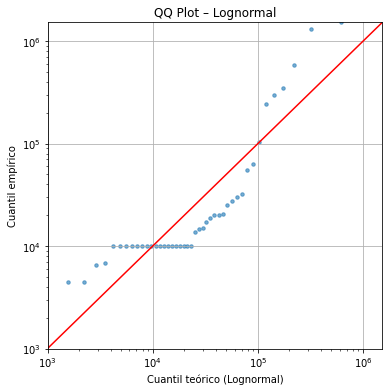

In [37]:
# 1. Ordenar severidades empíricas
sev_sorted = np.sort(sev_obs)
n = len(sev_sorted)

# 2. Probabilidades empíricas
probs = (np.arange(1, n + 1) - 0.5) / n

# 3. Cuantiles teóricos lognormal
theo_q = lognorm.ppf(
    probs,
    s=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

# 4. Límites comunes para ambos ejes
q_min = min(sev_sorted.min(), theo_q.min())
q_max = max(sev_sorted.max(), theo_q.max())

# 5. QQ plot
plt.figure(figsize=(6, 6))
plt.scatter(theo_q, sev_sorted, s=12, alpha=0.6)
plt.plot([q_min, q_max], [q_min, q_max], color="red")

plt.ylim(1e3, q_max)
plt.xlim(1e3, q_max)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Cuantil teórico (Lognormal)")
plt.ylabel("Cuantil empírico")
plt.title("QQ Plot – Lognormal")
plt.grid(True)

plt.show()


##### 4.1.4.2. PP Plot

In [26]:
def pp_plot(p_emp, p_theo, title):
    plt.figure(figsize=(6, 6))
    plt.scatter(p_theo, p_emp, s=18, alpha=0.7)
    plt.plot([0, 1], [0, 1], color="red", lw=2)
    plt.xlabel("Probabilidad teórica")
    plt.ylabel("Probabilidad empírica")
    plt.title(title)
    plt.grid(True)
    plt.show()

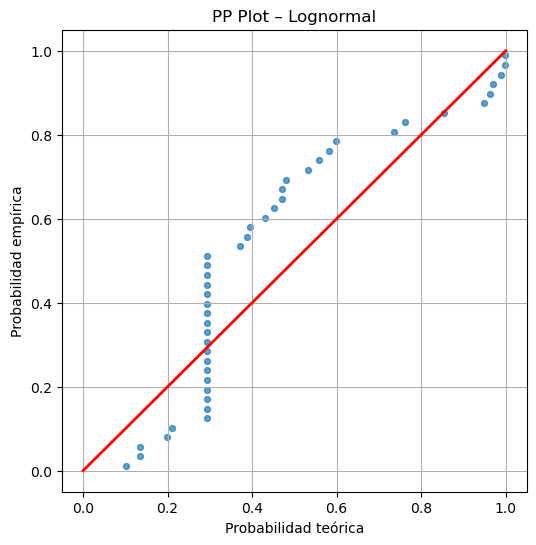

In [27]:
# 1. Ordenar datos
sev_sorted = np.sort(sev_obs)
n = len(sev_sorted)

# 2. Probabilidades empíricas
p_emp = (np.arange(1, n + 1) - 0.5) / n

# 3. Probabilidades teóricas lognormal
p_theo_lognorm = lognorm.cdf(
    sev_sorted,
    s=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

# 4. PP plot
pp_plot(p_emp, p_theo_lognorm, "PP Plot – Lognormal")


##### 4.1.4.3. Kolmogorov-Smirnov Test

In [40]:
ks_ln = kstest(
    sev_obs,
    'lognorm',
    args=(sigma_hat, loc_hat, scale_hat)
)

print("KS statistic:", ks_ln.statistic)
print("KS p-value:", ks_ln.pvalue)


KS statistic: 0.23041728873828093
KS p-value: 0.015496137089372586


##### 4.1.4.4. Anderson Test

In [39]:
# Transformar a normal usando log
log_sev = np.log(sev_obs)

ad_ln = anderson(log_sev, dist="norm")

print("AD statistic:", ad_ln.statistic)
print("Critical values:", ad_ln.critical_values)
print("Significance levels:", ad_ln.significance_level)

AD statistic: 3.9365457259979877
Critical values: [0.534 0.609 0.73  0.852 1.013]
Significance levels: [15.  10.   5.   2.5  1. ]


##### 4.1.4.5. Cramer-von-Mises Test

In [30]:
cvm_ln = cramervonmises(
    sev_obs,
    lambda x: lognorm.cdf(x, s=sigma_hat, loc=loc_hat, scale=scale_hat)
)

print("CvM statistic:", cvm_ln.statistic)
print("CvM p-value:", cvm_ln.pvalue)

CvM statistic: 0.738825785123512
CvM p-value: 0.009900932958905595


##### 4.1.4.6. AIC y BIC

In [41]:
def aic_bic(loglik, k, n):
    aic = 2*k - 2*loglik
    bic = k*np.log(n) - 2*loglik
    return aic, bic


In [42]:
loglik_ln = np.sum(lognorm.logpdf(sev_obs, s=sigma_hat, scale=scale_hat))
aic_ln, bic_ln = aic_bic(loglik_ln, k=2, n=len(sev_obs))

In [43]:
print('AIC: ', aic_ln)
print('BIC: ', bic_ln)

AIC:  1042.899819949928
BIC:  1046.4681992177645


#### 4.1.5. Simulación de pérdidas anuales

In [48]:
import numpy as np
import pandas as pd
from scipy.stats import poisson, lognorm

def sim_annual_loss_zip_lognormal_detail(
    panel_sub,
    lambda_hat,
    p_zero,
    sigma,
    loc,
    scale,
    retention=12_000_000
):
    n = len(panel_sub)

    # Zeros estructurales
    is_active = np.random.uniform(size=n) > p_zero

    # Frecuencia Poisson (ANUAL)
    mu = lambda_hat * panel_sub["exposicion_anual"].values
    freq = np.zeros(n, dtype=int)
    freq[is_active] = poisson.rvs(mu[is_active])

    n_claims = int(freq.sum())

    if n_claims == 0:
        return 0.0, np.array([]), np.array([]), 0

    # Severidad
    sev = lognorm.rvs(
        s=sigma,
        loc=loc,
        scale=scale,
        size=n_claims
    )

    sev_retained = np.minimum(sev, retention)

    total_loss = sev_retained.sum()

    return total_loss, sev, sev_retained, n_claims


In [51]:
def montecarlo_annual_losses_detail(
    sim_func,
    n_sim=2_000_000,
    random_seed=123,
    **sim_kwargs
):
    np.random.seed(random_seed)

    losses = np.zeros(n_sim)
    freqs = np.zeros(n_sim, dtype=int)

    severities_sim_all = []
    severities_ret_all = []

    for i in range(n_sim):
        L, sev_sim, sev_ret, n = sim_func(**sim_kwargs)

        losses[i] = L
        freqs[i] = n

        severities_sim_all.append(sev_sim)
        severities_ret_all.append(sev_ret)

        if (i + 1) % 5_000 == 0:
            print(f"{i + 1:,} simulaciones")

    return losses, severities_sim_all, severities_ret_all, freqs


In [ ]:

losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=2_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)




5,000 simulaciones
10,000 simulaciones
15,000 simulaciones
20,000 simulaciones
25,000 simulaciones
30,000 simulaciones
35,000 simulaciones
40,000 simulaciones
45,000 simulaciones
50,000 simulaciones
55,000 simulaciones
60,000 simulaciones
65,000 simulaciones
70,000 simulaciones
75,000 simulaciones
80,000 simulaciones
85,000 simulaciones
90,000 simulaciones
95,000 simulaciones
100,000 simulaciones
105,000 simulaciones
110,000 simulaciones
115,000 simulaciones
120,000 simulaciones
125,000 simulaciones
130,000 simulaciones
135,000 simulaciones
140,000 simulaciones
145,000 simulaciones
150,000 simulaciones
155,000 simulaciones
160,000 simulaciones
165,000 simulaciones
170,000 simulaciones
175,000 simulaciones
180,000 simulaciones
185,000 simulaciones
190,000 simulaciones
195,000 simulaciones
200,000 simulaciones
205,000 simulaciones
210,000 simulaciones
215,000 simulaciones
220,000 simulaciones
225,000 simulaciones
230,000 simulaciones
235,000 simulaciones
240,000 simulaciones
245,000 simu

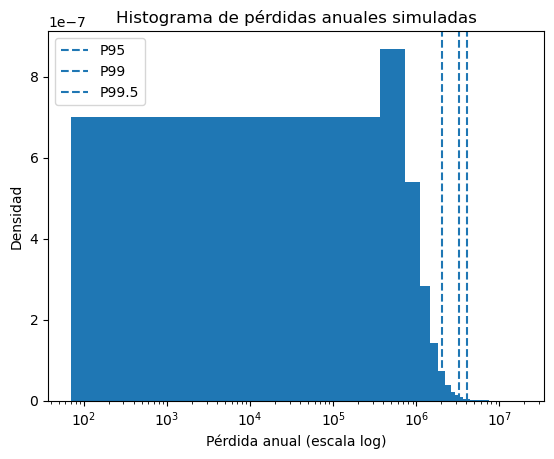

In [37]:
plt.figure()

losses_pos = losses[losses > 0]
plt.hist(losses_pos, bins=50, density=True)
plt.xscale("log")

for q, label in zip([0.95, 0.99, 0.995], ["P95", "P99", "P99.5"]):
    plt.axvline(
        np.quantile(losses, q),
        linestyle="--",
        label=label
    )

plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Densidad")
plt.title("Histograma de pérdidas anuales simuladas")
plt.legend()
plt.show()


In [ ]:
plt.figure()
plt.hist(losses_pos, bins=50)
plt.xscale("log")
plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Frecuencia")
plt.title("Histograma de pérdidas anuales simuladas")
plt.show()


#### 4.1.6. Revisión de convergencia

In [53]:
def convergence_metrics(losses, freqs, checkpoints):
    rows = []

    for n in checkpoints:
        L = losses[:n]
        F = freqs[:n]

        rows.append({
            "n_sim": n,
            "mean_loss": L.mean(),
            "var_loss": L.var(ddof=1),
           "sd_loss": L.std(ddof=1),
            "p90": np.quantile(L, 0.90),
            "p95": np.quantile(L, 0.95),
            "p99": np.quantile(L, 0.99),
            "freq_mean": F.mean()
        })

    return pd.DataFrame(rows)


In [58]:
losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=5_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat
)

checkpoints = np.arange(1_000, 5_000_001, 1_000)
df_conv = convergence_metrics(losses, freqs, checkpoints)


5,000 simulaciones
10,000 simulaciones
15,000 simulaciones
20,000 simulaciones
25,000 simulaciones
30,000 simulaciones
35,000 simulaciones
40,000 simulaciones
45,000 simulaciones
50,000 simulaciones
55,000 simulaciones
60,000 simulaciones
65,000 simulaciones
70,000 simulaciones
75,000 simulaciones
80,000 simulaciones
85,000 simulaciones
90,000 simulaciones
95,000 simulaciones
100,000 simulaciones
105,000 simulaciones
110,000 simulaciones
115,000 simulaciones
120,000 simulaciones
125,000 simulaciones
130,000 simulaciones
135,000 simulaciones
140,000 simulaciones
145,000 simulaciones
150,000 simulaciones
155,000 simulaciones
160,000 simulaciones
165,000 simulaciones
170,000 simulaciones
175,000 simulaciones
180,000 simulaciones
185,000 simulaciones
190,000 simulaciones
195,000 simulaciones
200,000 simulaciones
205,000 simulaciones
210,000 simulaciones
215,000 simulaciones
220,000 simulaciones
225,000 simulaciones
230,000 simulaciones
235,000 simulaciones
240,000 simulaciones
245,000 simu

KeyboardInterrupt: 

In [55]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(df_conv["n_sim"], df_conv["mean_loss"], label="Media")
plt.plot(df_conv["n_sim"], df_conv["p95"], label="P95")
plt.plot(df_conv["n_sim"], df_conv["p99"], label="P99")
plt.xlabel("Número de simulaciones")
plt.ylabel("Pérdida anual")
plt.legend()
plt.title("Convergencia de pérdida anual")
plt.show()


NameError: name 'df_conv' is not defined

<Figure size 432x288 with 0 Axes>

NameError: name 'df_conv' is not defined

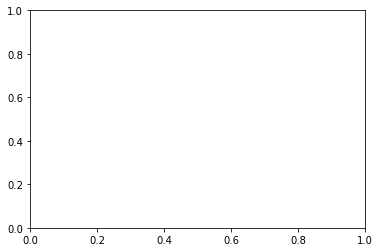

In [57]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()

# Eje izquierdo: media y cuantiles
ax1.plot(df_conv["n_sim"], df_conv["mean_loss"], label="Media")
ax1.plot(df_conv["n_sim"], df_conv["p95"], label="P95")
ax1.plot(df_conv["n_sim"], df_conv["p99"], label="P99")

ax1.set_xlabel("Número de simulaciones")
ax1.set_ylabel("Pérdida anual")
ax1.set_title("Convergencia de métricas de pérdida anual")

# Eje derecho: desviación estándar (mejor que varianza)
ax2 = ax1.twinx()
ax2.plot(
    df_conv["n_sim"],
    df_conv["sd_loss"],
    linestyle="--",
    label="Desv. estándar"
)
ax2.set_ylabel("Desviación estándar")

# Leyenda combinada
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.show()


In [56]:
df_conv["p99_rel_change"] = df_conv["p99"].pct_change().abs()
df_conv["mean_rel_change"] = df_conv["mean_loss"].pct_change().abs()


NameError: name 'df_conv' is not defined

In [44]:
df_conv.tail(100)[
    ["n_sim", "mean_rel_change", "p99_rel_change"]
]


,n_sim,mean_rel_change,p99_rel_change
4900,4901000,0,0
4901,4902000,0,0
4902,4903000,0,0
4903,4904000,0,0
4904,4905000,0,0
...,...,...,...
4995,4996000,0,0
4996,4997000,0,0
4997,4998000,0,0
4998,4999000,0,0


In [45]:
def mc_se(x):
    return x.std(ddof=1) / np.sqrt(len(x))

df_conv["mean_se"] = [
    mc_se(losses[:n]) for n in df_conv["n_sim"]
]


#### 4.1.6. Verificación de métricas de simulaciones

In [46]:
print(freqs.mean())

12.4885658


In [47]:
print((panel["n_siniestros"] > 0).mean())
print(1-p_zero)

df_siniestros["Fecha ocurrido"] = pd.to_datetime(df_siniestros["Fecha ocurrido"])
df_siniestros["anio"] = df_siniestros["Fecha ocurrido"].dt.year

df_siniestros.groupby("anio").size()

print(df_siniestros.groupby("anio").size().mean())

0.0064861816130851666
0.010785100221572752
8.8


In [48]:
all_sev = np.concatenate(sev_ret_all)

print(all_sev.mean())

print(np.quantile(all_sev, [0.5, 0.9, 0.95, 0.99]))


64257.12565984331
[ 22269.17280485 143931.2664763  244265.67742682 659273.55396159]


In [49]:
summary_table_ext = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Media",
        "Mediana",
        "Desv. estándar",
        "P90",
        "P95",
        "P99",
        "P99.5",
        "Máximo"
    ],
    "Valor": [
        len(losses),
        losses.mean(),
        np.median(losses),
        losses.std(ddof=1),
        np.quantile(losses, 0.90),
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
        np.quantile(losses, 0.995),
        losses.max()
    ]
})


In [50]:
summary_table_ext

,Estadístico,Valor
0,Observaciones,"5,000,000"
1,Media,"802,479"
2,Mediana,"633,625"
3,Desv. estándar,"699,837"
4,P90,"1,572,763"
5,P95,"2,015,744"
6,P99,"3,304,578"
7,P99.5,"4,048,256"
8,Máximo,"18,467,405"


#### 4.1.7. Exportar base

In [51]:
df_annual = pd.DataFrame({
    "sim_id": np.arange(1, len(losses) + 1),
    "loss_annual": losses,
    "n_claims": freqs
})

In [ ]:
rows = []

for sim_id, (sev_sim, sev_ret) in enumerate(
        zip(sev_sim_all, sev_ret_all), start=1
    ):
    for claim_id, (s_sim, s_ret) in enumerate(
            zip(sev_sim, sev_ret), start=1
        ):
        rows.append({
            "sim_id": sim_id,
            "claim_id": claim_id,
            "severity_simulada": s_sim,
            "severity_retenida": s_ret
        })

df_claims = pd.DataFrame(rows)


In [ ]:
# Retención bien aplicada
(df_claims["severity_retenida"] <= df_claims["severity_simulada"]).all()

# Reconstrucción de pérdidas anuales
check = (
    df_claims
    .groupby("sim_id")["severity_retenida"]
    .sum()
    .values
)

np.allclose(check, losses[losses > 0])


In [ ]:
df_annual.to_csv("sim_annual_results_lognormal.csv", index=False)
df_claims.to_csv("sim_claims_lognormal.csv", index=False)


#### 4.1.8. Test de estrés

In [ ]:
def sim_annual_loss_zip_lognormal_detail(
    panel_sub,
    lambda_hat,
    p_zero,
    sigma,
    loc,
    scale,
    retention=12_000_000,
    p_bad=0.05,
    z_bad=4.0
):
    n = len(panel_sub)

    # Stress anual común
    if np.random.rand() < p_bad:
        Z = z_bad
    else:
        Z = 1.0

    # Zeros estructurales
    is_active = np.random.uniform(size=n) > p_zero

    # Frecuencia Poisson con stress
    mu = Z * lambda_hat * panel_sub["exposicion_anual"].values
    freq = np.zeros(n, dtype=int)
    freq[is_active] = poisson.rvs(mu[is_active])

    n_claims = int(freq.sum())
    if n_claims == 0:
        return 0.0, np.array([]), np.array([]), 0

    # Severidad
    sev = lognorm.rvs(
        s=sigma,
        loc=loc,
        scale=scale,
        size=n_claims
    )

    sev_retained = np.minimum(sev, retention)

    return sev_retained.sum(), sev, sev_retained, n_claims


In [ ]:
def montecarlo_annual_losses_detail(
    sim_func,
    n_sim=2_000_000,
    random_seed=123,
    **sim_kwargs
):
    np.random.seed(random_seed)

    losses = np.zeros(n_sim)
    freqs = np.zeros(n_sim, dtype=int)

    severities_sim_all = []
    severities_ret_all = []

    for i in range(n_sim):
        L, sev_sim, sev_ret, n = sim_func(**sim_kwargs)

        losses[i] = L
        freqs[i] = n

        severities_sim_all.append(sev_sim)
        severities_ret_all.append(sev_ret)

        if (i + 1) % 1_000 == 0:
            print(f"{i + 1:,} simulaciones")

    return losses, severities_sim_all, severities_ret_all, freqs


In [ ]:
losses, sev_sim_all, sev_ret_all, freqs = montecarlo_annual_losses_detail(
    sim_func=sim_annual_loss_zip_lognormal_detail,
    n_sim=2_000_000,
    panel_sub=panel_sub,
    lambda_hat=lambda_hat,
    p_zero=p_zero,
    sigma=sigma_hat,
    loc=loc_hat,
    scale=scale_hat,
    p_bad=0.05,
    z_bad=4.0
)


In [ ]:
df_annual = pd.DataFrame({
    "sim_id": np.arange(1, len(losses) + 1),
    "loss_annual": losses,
    "n_claims": freqs
})

In [ ]:
rows = []

for sim_id, (sev_sim, sev_ret) in enumerate(
    zip(sev_sim_all, sev_ret_all), start=1
):
    # Si no hubo siniestros, no se agregan filas
    if len(sev_sim) == 0:
        continue

    for claim_id, (s_sim, s_ret) in enumerate(
        zip(sev_sim, sev_ret), start=1
    ):
        rows.append({
            "sim_id": sim_id,
            "claim_id": claim_id,
            "severity_simulada": float(s_sim),
            "severity_retenida": float(s_ret)
        })

df_claims = pd.DataFrame(rows)


In [ ]:
assert (df_claims["severity_retenida"] <= df_claims["severity_simulada"]).all()


In [ ]:
check = (
    df_claims
    .groupby("sim_id")["severity_retenida"]
    .sum()
)

# Comparar contra pérdidas positivas
losses_pos = pd.Series(losses, index=df_annual["sim_id"]).loc[check.index]

assert np.allclose(check.values, losses_pos.values)


In [ ]:
summary_table_ext = pd.DataFrame({
    "Estadístico": [
        "Observaciones",
        "Media",
        "Mediana",
        "Desv. estándar",
        "P90",
        "P95",
        "P99",
        "P99.5",
        "Máximo"
    ],
    "Valor": [
        len(losses),
        losses.mean(),
        np.median(losses),
        losses.std(ddof=1),
        np.quantile(losses, 0.90),
        np.quantile(losses, 0.95),
        np.quantile(losses, 0.99),
        np.quantile(losses, 0.995),
        losses.max()
    ]
})


In [ ]:
summary_table_ext

In [ ]:
plt.figure()

losses_pos = losses[losses > 0]
plt.hist(losses_pos, bins=50, density=True)
plt.xscale("log")

for q, label in zip([0.95, 0.99, 0.995], ["P95", "P99", "P99.5"]):
    plt.axvline(
        np.quantile(losses, q),
        linestyle="--",
        label=label
    )

plt.xlabel("Pérdida anual (escala log)")
plt.ylabel("Densidad")
plt.title("Histograma de pérdidas anuales simuladas")
plt.legend()
plt.show()

In [ ]:
df_annual.to_csv(
    "sim_annual_results_lognormal_test-estres.csv",
    index=False
)

df_claims.to_csv(
    "sim_claims_lognormal_test-estres.csv",
    index=False
)
